# BayMorph simulated-galaxy validation

Minimal end-to-end validation of a simulated single-Sérsic galaxy.

This notebook intentionally keeps all scientific logic inside BayMorph.

In [6]:
from pathlib import Path
import os

from baymorph import (
    BayMorphRunner,
    load_resolved_config,
    run_simulation_from_config,
)

if Path.cwd().name == "notebooks":
    os.chdir("..")

CONFIG_PATH = Path("configs/simulated_galaxy.yaml")
config = load_resolved_config(CONFIG_PATH)

print(f"Configuration: {CONFIG_PATH}")
print(f"Object: {config['object']['name']}")

Configuration: configs/simulated_galaxy.yaml
Object: simulated_galaxy_noiseless


## 1. Generate the simulated observation

In [7]:
run_simulation_from_config(config)

SyntheticObservation(image=array([[ 0.03048646, -0.1039836 ,  0.07506   , ...,  0.01211802,
         0.01307664,  0.08237553],
       [-0.00591345, -0.07291383, -0.04143237, ..., -0.00915378,
        -0.05308196,  0.22141548],
       [-0.04518021, -0.06657283,  0.04341599, ...,  0.23310269,
         0.08194498, -0.03341185],
       ...,
       [ 0.0629084 , -0.05757326,  0.0893311 , ..., -0.06787291,
        -0.05262395,  0.18701412],
       [ 0.10271995,  0.0004265 , -0.20361922, ..., -0.04592339,
         0.20108919, -0.04916298],
       [-0.0475579 ,  0.08534504, -0.05738768, ..., -0.15298126,
        -0.03656152,  0.08769391]], shape=(1000, 1000)), intrinsic_image=array([[1.46775425e-05, 1.47592413e-05, 1.48411251e-05, ...,
        2.22752521e-07, 2.21282749e-07, 2.19823401e-07],
       [1.47592413e-05, 1.48417875e-05, 1.49245248e-05, ...,
        2.24235036e-07, 2.22754002e-07, 2.21283483e-07],
       [1.48411251e-05, 1.49245248e-05, 1.50081216e-05, ...,
        2.25728173e-07, 2.

## 2. Initialize the pipeline

In [8]:
runner = BayMorphRunner(config)

## 3. Prepare the image

In [9]:
runner.prepare_image()

✓ Image preparation completed


## 4. Fit the configured model

In [10]:
runner.fit()


────────────────────────────────────────────────────
Running Dynesty fit: single_sersic
ndim=8, nlive=50, sample=rslice, bound=multi
────────────────────────────────────────────────────


────────────────────────────────────────────────────
Completed Dynesty fit: single_sersic
logZ=106662
logZerr=1.95902
ncall=700457
────────────────────────────────────────────────────
✓ Bayesian fitting completed


## 5. Generate diagnostics

In [11]:
runner.diagnostics()

✓ Corner plots generated
✓ Residual maps generated
✓ Radial profiles generated
✓ All diagnostics generated


## 6. Inspect the fitted parameters

In [12]:
result = runner.fit_result

print("Best parameters:")
for name, value in result.best_parameters.items():
    print(f"{name:>8s}: {value:.8g}")

print("\nFit statistics:")
for name, value in result.statistics.items():
    print(f"{name:>14s}: {value:.8g}")

Best parameters:
    flux: 100021.36
      re: 10.082667
       n: 4.0726301
       q: 0.49973195
   theta: 0.78565712
      x0: 175
      y0: 176
     sky: -0.0071677388

Fit statistics:
          chi2: 121139.86
  reduced_chi2: 1.0011973
          ndof: 120995


✓ Image preparation completed


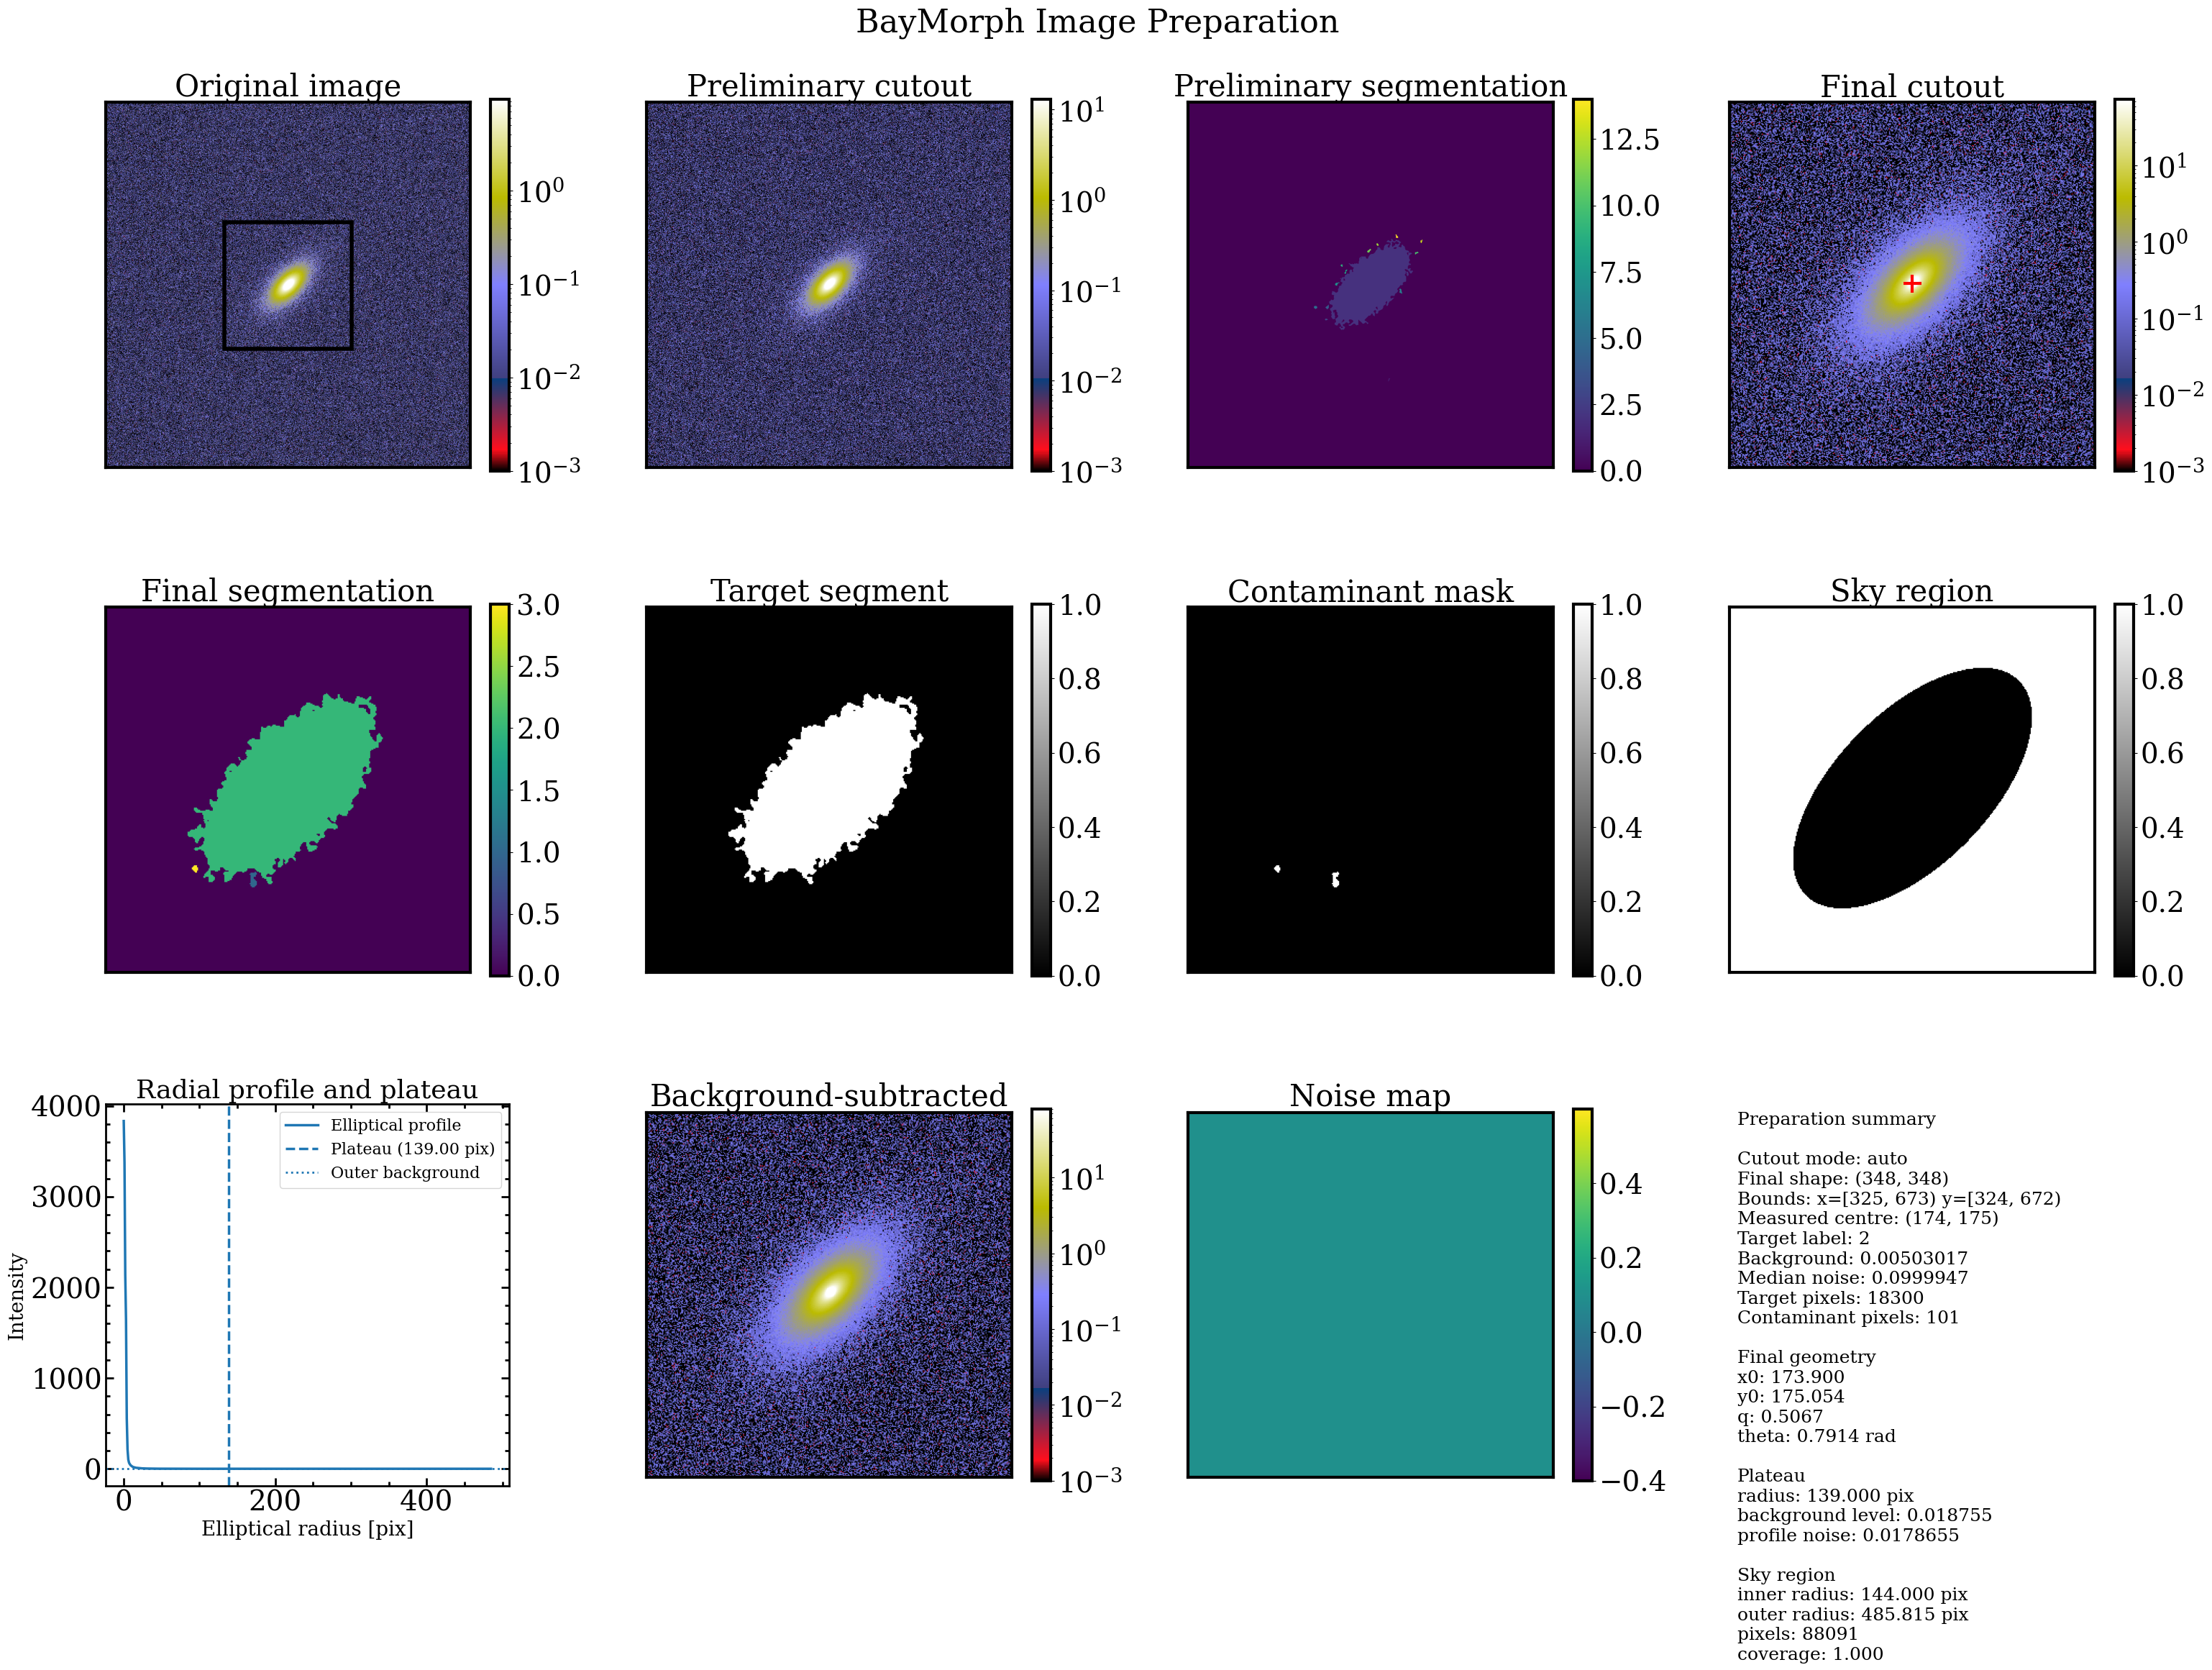

(<Figure size 3000x2200 with 22 Axes>,
 array([[<Axes: title={'center': 'Original image'}>,
         <Axes: title={'center': 'Preliminary cutout'}>,
         <Axes: title={'center': 'Preliminary segmentation'}>,
         <Axes: title={'center': 'Final cutout'}>],
        [<Axes: title={'center': 'Final segmentation'}>,
         <Axes: title={'center': 'Target segment'}>,
         <Axes: title={'center': 'Contaminant mask'}>,
         <Axes: title={'center': 'Sky region'}>],
        [<Axes: title={'center': 'Radial profile and plateau'}, xlabel='Elliptical radius [pix]', ylabel='Intensity'>,
         <Axes: title={'center': 'Background-subtracted'}>,
         <Axes: title={'center': 'Noise map'}>, <Axes: >]], dtype=object))

In [13]:
from baymorph.plotting.report import (
    plot_image_preparation_report,
)

products = runner.prepare_image(
    return_result=True,
)

plot_image_preparation_report(
    products,
    output_path=(
        "runs/simulated_galaxy_noiseless/"
        "image_preparation_report.pdf"
    ),
)

In [14]:
import numpy as np

print("Mode:", products.cutout_mode)
print("Preliminary:", products.preliminary_cutout.shape)
print("Final:", products.cutout.shape)
print("Bounds:", products.cutout_bounds)
print("Plateau radius:", products.plateau.radius)
print("Sky pixels:", products.sky_region.n_pixels)
print("Background:", products.background)
print("Noise:", float(np.nanmedian(products.noise)))

Mode: auto
Preliminary: (864, 864)
Final: (348, 348)
Bounds: {'xmin': 325, 'xmax': 673, 'ymin': 324, 'ymax': 672}
Plateau radius: 139.0
Sky pixels: 88091
Background: 0.005030167868896995
Noise: 0.09999467722846862
